# Week 9 - Gradient Boosting

Gradient boosting builds trees **in sequence**: start with a flat guess, measure the residuals (what is still unexplained), fit a small tree to those residuals, add a *scaled* copy of its predictions to the running total, and repeat. A random forest averages many independent deep trees to cut variance; boosting stacks many shallow trees to cut bias. The knobs from the reading are the **learning rate**, the **number of trees**, the **tree depth**, and **regularization** (minimum samples per leaf, row subsampling, a leaf penalty).

My capstone proposal commits to **XGBoost**, which is an optimized implementation of the same idea, so I use scikit-learn's `GradientBoosting*` for the small tabular data (where I can see each mechanism) and XGBoost for the sparse text matrix.

| Dataset | Target | What I want to learn |
|---|---|---|
| E-commerce (`ecommerce_data.csv`) | `Profit > 0`; also `Profit` itself | learning rate vs. number of trees, depth, regularization, and whether boosting beats the Week 6 forest |
| Amazon reviews (`amazon_review_data.csv`) | negative review | can boosted trees on TF-IDF compete with the Week 5 linear SVM? |
| Instacart (`insta_df_sample.csv`) | `reordered` | does boosting improve on the Week 6 forest (AUC 0.783) on weak-signal data? |

As in earlier weeks: stratified 75/25 split with `random_state=42`, hyperparameters chosen by cross-validation on the **training** set only, and F1 on the minority class (not accuracy) for the imbalanced targets.

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, RandomizedSearchCV)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, precision_score, recall_score, r2_score, mean_squared_error)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
np.random.seed(42)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

def scores_row(name, y_true, proba, preds, minority_label):
    return {"model": name, "accuracy": accuracy_score(y_true, preds), "roc_auc": roc_auc_score(y_true, proba),
            "f1_minority": f1_score(y_true, preds, pos_label=minority_label),
            "precision_minority": precision_score(y_true, preds, pos_label=minority_label, zero_division=0),
            "recall_minority": recall_score(y_true, preds, pos_label=minority_label)}

## Part 0 - The reading's house-price example, by hand and in code

Three listings with actual prices 1.8, 1.3, 2.6 (hundreds of thousands). Start from the mean (1.9), fit a stump on a feature that separates sample 3 from samples 1 and 2, and add the stump's prediction scaled by a learning rate of 0.5. The reading uses illustrative stump values (-0.4, -0.4, +0.9); a real stump predicts the *mean residual in each leaf* (-0.35 for samples 1-2 and +0.70 for sample 3), so I show both. I also check the quiz formula: next total = last total + learning rate x predicted residual.

In [ ]:
actual = np.array([1.8, 1.3, 2.6]); color = np.array([[0], [0], [1]])          # "orange, orange, blue"
pred = np.full(3, actual.mean()); print(f"round 0: prediction {pred[0]:.2f}, residuals {np.round(actual - pred, 2)}")

# the reading's illustrative stump output, learning rate 0.5
reading_stump = np.array([-0.4, -0.4, 0.9]); lr = 0.5
print("reading's numbers: new totals", pred + lr * reading_stump, "-> residuals", np.round(actual - (pred + lr * reading_stump), 2))

# a real stump (mean residual per leaf) on the same feature, boosted for several rounds
pred = np.full(3, actual.mean())
for r in range(1, 6):
    resid = actual - pred
    stump = DecisionTreeRegressor(max_depth=1).fit(color, resid)
    pred = pred + lr * stump.predict(color)
    print(f"round {r}: totals {np.round(pred, 3)}, residuals {np.round(actual - pred, 3)}")

print("\nquiz check: last total 1, learning rate 0.3, stump predicts residual 3 ->", 1 + 0.3 * 3)

round 0: prediction 1.90, residuals [-0.1 -0.6  0.7]
reading's numbers: new totals [1.7  1.7  2.35] -> residuals [ 0.1  -0.4   0.25]
round 1: totals [1.725 1.725 2.25 ], residuals [ 0.075 -0.425  0.35 ]
round 2: totals [1.638 1.638 2.425], residuals [ 0.162 -0.338  0.175]
round 3: totals [1.594 1.594 2.512], residuals [ 0.206 -0.294  0.087]
round 4: totals [1.572 1.572 2.556], residuals [ 0.228 -0.272  0.044]
round 5: totals [1.561 1.561 2.578], residuals [ 0.239 -0.261  0.022]

quiz check: last total 1, learning rate 0.3, stump predicts residual 3 -> 1.9


## Part A - E-commerce: is this order profitable?

Same 29 features and the same split as Weeks 4-8. Boosted trees need no scaling.

In [ ]:
df = pd.read_csv("ecommerce_data.csv")
numeric_cols = ["Sales", "Quantity", "Discount"]
categorical_cols = ["Segment", "Region", "Ship Mode", "Category", "Sub-Category"]
X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True).astype(float)
y = (df["Profit"] > 0).astype(int).values            # 1 = profitable, 0 = unprofitable (minority, ~19%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(X.shape, f"profitable share {y.mean():.1%}; majority-class baseline accuracy {max(y.mean(), 1 - y.mean()):.3f}")

# a single stump and a single depth-3 tree, to see what boosting adds
for d in [1, 3]:
    g = GradientBoostingClassifier(n_estimators=1, max_depth=d, learning_rate=1.0, random_state=42).fit(X_train, y_train)
    print(f"1 tree, depth {d}: test AUC {roc_auc_score(y_test, g.predict_proba(X_test)[:, 1]):.3f}")

(3312, 29) profitable share 80.7%; majority-class baseline accuracy 0.807
1 tree, depth 1: test AUC 0.849
1 tree, depth 3: test AUC 0.942


### A1. Learning rate vs. number of trees

I hold depth at 2 and let each model grow to 600 trees, tracking AUC on an **inner validation split** carved from the training set (so the test set is never used to choose anything). Small learning rates need many more trees to get anywhere, and a large learning rate can reach its best score quickly and then get worse.

 learning_rate  best_n_trees  best_val_AUC  val_AUC_at_600  train_AUC_at_600
          1.00             4         0.970           0.951             0.967
          0.30           173         0.981           0.977             1.000
          0.10           572         0.981           0.981             0.998
          0.03           439         0.980           0.980             0.990


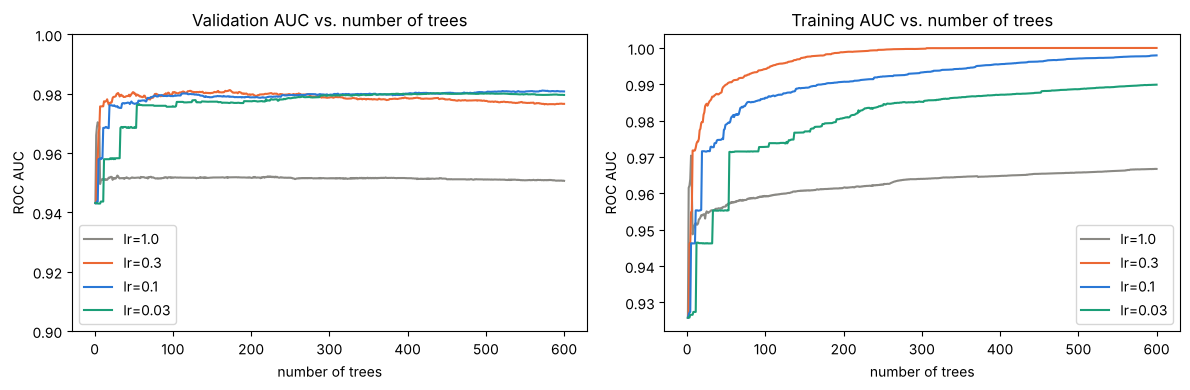

In [ ]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42, stratify=y_train)
n_trees = 600; curves, rows = {}, []
for lr in [1.0, 0.3, 0.1, 0.03]:
    g = GradientBoostingClassifier(n_estimators=n_trees, learning_rate=lr, max_depth=2, random_state=42).fit(X_fit, y_fit)
    val_auc = [roc_auc_score(y_val, p[:, 1]) for p in g.staged_predict_proba(X_val)]
    tr_auc = [roc_auc_score(y_fit, p[:, 1]) for p in g.staged_predict_proba(X_fit)]
    curves[lr] = (tr_auc, val_auc)
    rows.append({"learning_rate": lr, "best_n_trees": int(np.argmax(val_auc)) + 1, "best_val_AUC": max(val_auc), "val_AUC_at_600": val_auc[-1], "train_AUC_at_600": tr_auc[-1]})
print(pd.DataFrame(rows).round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cols = {1.0: "#8a8984", 0.3: ORANGE, 0.1: BLUE, 0.03: "#1b9e77"}
for lr, (tr_a, va_a) in curves.items():
    ax[0].plot(range(1, n_trees + 1), va_a, color=cols[lr], label=f"lr={lr}"); ax[1].plot(range(1, n_trees + 1), tr_a, color=cols[lr], label=f"lr={lr}")
ax[0].set_title("Validation AUC vs. number of trees"); ax[1].set_title("Training AUC vs. number of trees")
for a in ax: a.set_xlabel("number of trees"); a.set_ylabel("ROC AUC"); a.legend()
ax[0].set_ylim(0.9, 1.0); plt.tight_layout(); plt.show()

### A2. Tree depth of each weak learner

Depth controls how much interaction each tree can capture. At learning rate 0.1 with 300 trees, I compare training AUC against 5-fold CV AUC for depths 1 through 8. A depth-1 stump can only model each feature separately (an additive model); deeper trees can combine, say, `Discount` and `Sub-Category`.

 max_depth  train_AUC  cv_AUC
         1      0.983   0.979
         2      0.991   0.978
         3      0.999   0.976
         4      1.000   0.974
         6      1.000   0.971
         8      1.000   0.968


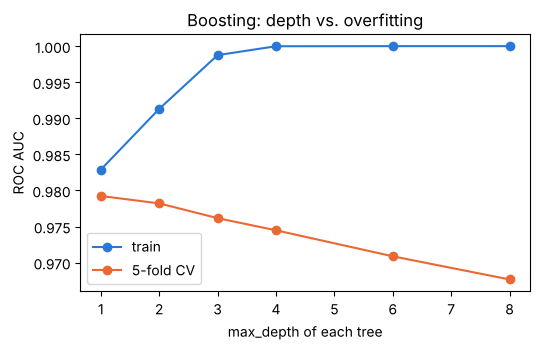

In [ ]:
rows = []
for d in [1, 2, 3, 4, 6, 8]:
    g = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=d, random_state=42)
    cv = cross_val_score(g, X_train, y_train, cv=cv5, scoring="roc_auc").mean()
    tr = roc_auc_score(y_train, g.fit(X_train, y_train).predict_proba(X_train)[:, 1])
    rows.append({"max_depth": d, "train_AUC": tr, "cv_AUC": cv})
depth_tbl = pd.DataFrame(rows); print(depth_tbl.round(3).to_string(index=False))
plt.figure(figsize=(5.5, 3.6)); plt.plot(depth_tbl.max_depth, depth_tbl.train_AUC, "-o", color=BLUE, label="train"); plt.plot(depth_tbl.max_depth, depth_tbl.cv_AUC, "-o", color=ORANGE, label="5-fold CV")
plt.xlabel("max_depth of each tree"); plt.ylabel("ROC AUC"); plt.legend(); plt.title("Boosting: depth vs. overfitting"); plt.tight_layout(); plt.show()

### A3. Regularization: row subsampling and minimum samples per leaf

Two of the three regularizers from the reading are available in scikit-learn: `subsample` (each tree sees a random fraction of the rows, which is "stochastic gradient boosting") and `min_samples_leaf` (no leaf may rest on only a handful of orders). Depth 3, learning rate 0.1, 300 trees, 5-fold CV AUC.

In [ ]:
grid = pd.DataFrame(index=[1.0, 0.8, 0.5], columns=[1, 5, 20, 50], dtype=float)
for ss in grid.index:
    for msl in grid.columns:
        g = GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, subsample=ss, min_samples_leaf=msl, random_state=42)
        grid.loc[ss, msl] = cross_val_score(g, X_train, y_train, cv=cv5, scoring="roc_auc").mean()
grid.index.name, grid.columns.name = "subsample", "min_samples_leaf"
print(grid.round(4))

min_samples_leaf      1       5       20      50
subsample                                       
1.0               0.9762  0.9777  0.9765  0.9757
0.8               0.9776  0.9779  0.9761  0.9747
0.5               0.9768  0.9763  0.9755  0.9756


### A4. Tuning with randomized search, then the test set

I tune on the full training set with 5-fold CV ROC AUC (30 random draws), then evaluate once on the held-out test set and compare with the earlier weeks.

In [ ]:
space = {"n_estimators": [100, 200, 300, 500], "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2], "max_depth": [2, 3, 4, 5],
         "subsample": [0.6, 0.8, 1.0], "min_samples_leaf": [1, 5, 10, 20], "max_features": [None, 0.5]}
search = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), space, n_iter=30, scoring="roc_auc", cv=cv5, random_state=42, n_jobs=2).fit(X_train, y_train)
print("best params:", search.best_params_, " CV AUC", round(search.best_score_, 4))
gb = search.best_estimator_
proba = gb.predict_proba(X_test)[:, 1]; pred = gb.predict(X_test)
ecom_gb = scores_row("Gradient boosting (tuned)", y_test, proba, pred, 0)
# same split, same minority class: reference models re-fit here so the comparison is exact
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, max_features=1.0, random_state=42, n_jobs=2).fit(X_train, y_train)
ecom_rf = scores_row("Random forest (Week 6 settings)", y_test, rf.predict_proba(X_test)[:, 1], rf.predict(X_test), 0)
print(pd.DataFrame([ecom_gb, ecom_rf]).set_index("model").round(3).to_string())

best params: {'subsample': 1.0, 'n_estimators': 200, 'min_samples_leaf': 5, 'max_features': None, 'max_depth': 3, 'learning_rate': 0.05}  CV AUC 0.9792


                                 accuracy  roc_auc  f1_minority  precision_minority  recall_minority
model                                                                                               
Gradient boosting (tuned)           0.948    0.977        0.854               0.933            0.788
Random forest (Week 6 settings)     0.944    0.980        0.844               0.925            0.775


### A5. What did the boosted model learn?

Permutation importance on the test set (the drop in ROC AUC when one feature is shuffled), the same measure I used in Week 6 because impurity-based importance favors high-cardinality features.

Discount                    0.4228
Sub-Category_Storage        0.0183
Category_Office Supplies    0.0152
Sales                       0.0028
Sub-Category_Chairs         0.0022
Sub-Category_Supplies       0.0019
Sub-Category_Bookcases      0.0016
Sub-Category_Copiers        0.0010


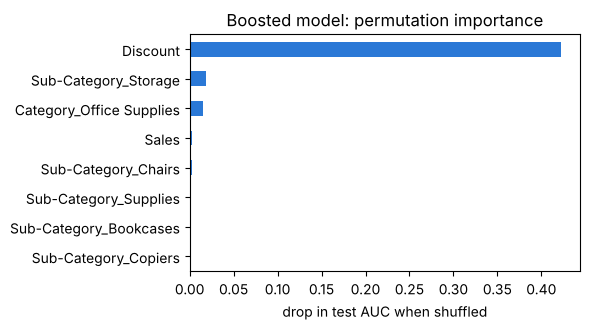

In [ ]:
pm = permutation_importance(gb, X_test, y_test, n_repeats=10, scoring="roc_auc", random_state=42, n_jobs=2)
imp = pd.Series(pm.importances_mean, index=X.columns).sort_values(ascending=False)
print(imp.head(8).round(4).to_string())
plt.figure(figsize=(6, 3.4)); imp.head(8)[::-1].plot.barh(color=BLUE); plt.xlabel("drop in test AUC when shuffled"); plt.title("Boosted model: permutation importance"); plt.tight_layout(); plt.show()

### A6. Regression: can boosting predict the *amount* of profit? (link back to Weeks 1-3)

Profit is heavy-tailed, and squared error lets a few extreme orders dominate the fit. Boosting allows other loss functions, so I compare squared error with the **Huber** loss (quadratic for small residuals, linear for large ones), against OLS and a random forest re-fit on the same split.

In [ ]:
yr = df["Profit"].values
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, yr, test_size=0.25, random_state=42)
def reg_row(name, m):
    p = m.fit(Xr_tr, yr_tr).predict(Xr_te); return {"model": name, "test_R2": r2_score(yr_te, p), "test_RMSE": np.sqrt(mean_squared_error(yr_te, p)), "test_MAE": np.mean(np.abs(yr_te - p))}
common = dict(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, min_samples_leaf=20, random_state=42)
reg = pd.DataFrame([reg_row("OLS", LinearRegression()),
                    reg_row("Random forest regressor", RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=2)),
                    reg_row("Gradient boosting, squared error", GradientBoostingRegressor(loss="squared_error", **common)),
                    reg_row("Gradient boosting, Huber", GradientBoostingRegressor(loss="huber", **common))])
print(reg.set_index("model").round(3).to_string())

                                  test_R2  test_RMSE  test_MAE
model                                                         
OLS                                 0.281    272.322    64.962
Random forest regressor             0.247    278.552    41.971
Gradient boosting, squared error    0.219    283.723    45.944
Gradient boosting, Huber            0.282    272.155    39.193


## Part B - Amazon reviews: boosted trees on text

Same text target and split as Weeks 5 and 8 (3-star reviews dropped; negative = rating 1-2). TF-IDF with unigrams and bigrams gives a sparse matrix with thousands of columns; XGBoost handles sparse input directly. Boosting has no `class_weight` argument, but `scale_pos_weight` (negatives / positives) plays the same role. I tune on 3-fold CV AUC, then choose the **classification threshold on out-of-fold training predictions** (the Week 8 method) so that the test set is only touched once.

In [ ]:
a = pd.read_csv("amazon_review_data.csv")
a = a[a["rating"] != 3].copy()
a["negative"] = (a["rating"] <= 2).astype(int)
a["full"] = a["title"].fillna("") + ". " + a["text"].fillna("")
tr, te = train_test_split(a, test_size=0.25, random_state=42, stratify=a["negative"])
ya_tr, ya_te = tr["negative"].values, te["negative"].values
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)
Xa_tr, Xa_te = tfidf.fit_transform(tr["full"]), tfidf.transform(te["full"])
spw = (ya_tr == 0).sum() / (ya_tr == 1).sum()
print(Xa_tr.shape, f"negative share {a['negative'].mean():.1%}; scale_pos_weight {spw:.1f}")

space_x = {"n_estimators": [200, 400], "learning_rate": [0.05, 0.1, 0.2], "max_depth": [3, 4, 6], "subsample": [0.8, 1.0], "colsample_bytree": [0.2, 0.5], "min_child_weight": [1, 5]}
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
sx = RandomizedSearchCV(XGBClassifier(tree_method="hist", scale_pos_weight=spw, random_state=42, n_jobs=2, eval_metric="logloss"), space_x, n_iter=10,
                        scoring="roc_auc", cv=cv3, random_state=42, n_jobs=1).fit(Xa_tr, ya_tr)
print("best params:", sx.best_params_, " CV AUC", round(sx.best_score_, 4))
xgb = sx.best_estimator_
oof = cross_val_predict(XGBClassifier(**xgb.get_params()), Xa_tr, ya_tr, cv=cv5, method="predict_proba")[:, 1]
ths = np.linspace(0.05, 0.95, 37); f1s = [f1_score(ya_tr, oof >= t) for t in ths]; t_star = ths[int(np.argmax(f1s))]
print(f"threshold chosen on training out-of-fold predictions: {t_star:.2f} (OOF F1 {max(f1s):.3f})")
pa = xgb.predict_proba(Xa_te)[:, 1]
text_default = scores_row("XGBoost, threshold 0.50", ya_te, pa, (pa >= 0.5).astype(int), 1)
text_final = scores_row(f"XGBoost, threshold {t_star:.2f}", ya_te, pa, (pa >= t_star).astype(int), 1)
print(pd.DataFrame([text_default, text_final]).set_index("model").round(3).to_string())

names = np.array(tfidf.get_feature_names_out())
gain = pd.Series(xgb.feature_importances_, index=names).sort_values(ascending=False)
print("\nmost important terms (gain):", ", ".join(gain.head(15).index))

(7029, 8000) negative share 12.4%; scale_pos_weight 7.0


best params: {'subsample': 0.8, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.2, 'colsample_bytree': 0.2}  CV AUC 0.9139


threshold chosen on training out-of-fold predictions: 0.55 (OOF F1 0.642)
                         accuracy  roc_auc  f1_minority  precision_minority  recall_minority
model                                                                                       
XGBoost, threshold 0.50     0.926     0.94        0.701               0.701            0.701
XGBoost, threshold 0.55     0.927     0.94        0.701               0.718            0.684

most important terms (gain): update reviews, perfect, highly recommend, great, waste money, love, reviews new, info, return, loves, asked, good thing, falling, perfectly, model


## Part C - Instacart: boosting on weak-signal data

Same seven features as Week 6's forest (`order_number`, `order_dow`, `order_hour_of_day`, `add_to_cart_order`, `days_since_prior_order` with missing filled as -1, plus integer codes for aisle and department; trees can split on codes without treating them as distances). The Week 6 forest reached CV AUC 0.779 and test AUC 0.783. Before tuning, I check how fast boosting overfits here with a large learning rate.

(11250, 7) reordered share 59.2%; majority-class baseline accuracy 0.592


 learning_rate  best_n_trees  best_val_AUC  val_AUC_at_400  train_AUC_at_400
          0.30            52         0.790           0.768             0.904
          0.05           216         0.789           0.788             0.827


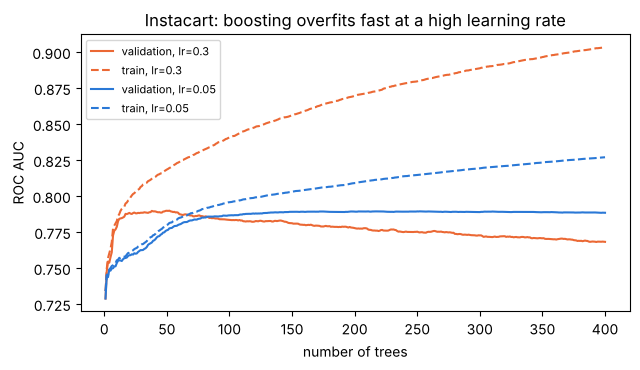

In [ ]:
ins = pd.read_csv("insta_df_sample.csv")
ins["days_since_prior"] = ins["days_since_prior_order"].fillna(-1)
ins["aisle_code"] = ins["aisle"].astype("category").cat.codes; ins["dept_code"] = ins["department"].astype("category").cat.codes
feats = ["order_number", "order_dow", "order_hour_of_day", "add_to_cart_order", "days_since_prior", "aisle_code", "dept_code"]
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(ins[feats], ins["reordered"].values, test_size=0.25, random_state=42, stratify=ins["reordered"])
Xi_fit, Xi_val, yi_fit, yi_val = train_test_split(Xi_tr, yi_tr, test_size=0.25, random_state=42, stratify=yi_tr)
print(Xi_tr.shape, f"reordered share {ins['reordered'].mean():.1%}; majority-class baseline accuracy {ins['reordered'].mean():.3f}")

rows, curves_i = [], {}
for lr in [0.3, 0.05]:
    g = GradientBoostingClassifier(n_estimators=400, learning_rate=lr, max_depth=3, random_state=42).fit(Xi_fit, yi_fit)
    va = [roc_auc_score(yi_val, p[:, 1]) for p in g.staged_predict_proba(Xi_val)]; trn = [roc_auc_score(yi_fit, p[:, 1]) for p in g.staged_predict_proba(Xi_fit)]
    curves_i[lr] = (trn, va); rows.append({"learning_rate": lr, "best_n_trees": int(np.argmax(va)) + 1, "best_val_AUC": max(va), "val_AUC_at_400": va[-1], "train_AUC_at_400": trn[-1]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
plt.figure(figsize=(6.5, 3.8))
for lr, (trn, va), c in [(0.3, curves_i[0.3], ORANGE), (0.05, curves_i[0.05], BLUE)]:
    plt.plot(range(1, 401), va, color=c, label=f"validation, lr={lr}"); plt.plot(range(1, 401), trn, color=c, ls="--", label=f"train, lr={lr}")
plt.xlabel("number of trees"); plt.ylabel("ROC AUC"); plt.legend(fontsize=8); plt.title("Instacart: boosting overfits fast at a high learning rate"); plt.tight_layout(); plt.show()

In [ ]:
space_i = {"n_estimators": [100, 200, 300], "learning_rate": [0.01, 0.03, 0.05, 0.1], "max_depth": [2, 3, 4, 5], "subsample": [0.6, 0.8, 1.0], "min_samples_leaf": [10, 20, 50, 100]}
si = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), space_i, n_iter=20, scoring="roc_auc", cv=cv5, random_state=42, n_jobs=2).fit(Xi_tr, yi_tr)
print("best params:", si.best_params_, " CV AUC", round(si.best_score_, 4))
gi = si.best_estimator_
pi = gi.predict_proba(Xi_te)[:, 1]
insta_gb = scores_row("Gradient boosting (tuned)", yi_te, pi, gi.predict(Xi_te), 0)
print(pd.DataFrame([insta_gb]).set_index("model").round(3).to_string())
pm = permutation_importance(gi, Xi_te, yi_te, n_repeats=10, scoring="roc_auc", random_state=42, n_jobs=2)
print("\npermutation importance (drop in test AUC):"); print(pd.Series(pm.importances_mean, index=feats).sort_values(ascending=False).round(4).to_string())

best params: {'subsample': 0.6, 'n_estimators': 300, 'min_samples_leaf': 20, 'max_depth': 2, 'learning_rate': 0.1}  CV AUC 0.7847
                           accuracy  roc_auc  f1_minority  precision_minority  recall_minority
model                                                                                         
Gradient boosting (tuned)     0.728     0.79        0.621               0.718            0.547



permutation importance (drop in test AUC):
order_number         0.1642
add_to_cart_order    0.0264
dept_code            0.0255
aisle_code           0.0200
days_since_prior     0.0172
order_hour_of_day    0.0007
order_dow           -0.0000


## Summary: boosting against the earlier weeks

Weeks 4-6 and 8 rows are copied from my earlier notebook outputs (same splits). The e-commerce random forest is re-fit above on this notebook's split with the Week 6 settings, so that comparison is exact.

In [ ]:
summary = pd.DataFrame([
    {"dataset": "E-commerce", "model": "Logistic regression (Week 4)", "roc_auc": 0.976, "f1_minority": 0.804},
    {"dataset": "E-commerce", "model": "RBF SVM (Week 5)", "roc_auc": 0.965, "f1_minority": 0.825},
    {"dataset": "E-commerce", "model": "Random forest (Week 6 settings, re-fit)", "roc_auc": ecom_rf["roc_auc"], "f1_minority": ecom_rf["f1_minority"]},
    {"dataset": "E-commerce", "model": "KNN (Week 8)", "roc_auc": 0.951, "f1_minority": 0.790},
    {"dataset": "E-commerce", "model": "Gradient boosting (tuned)", "roc_auc": ecom_gb["roc_auc"], "f1_minority": ecom_gb["f1_minority"]},
    {"dataset": "Amazon", "model": "TF-IDF + linear SVM (Week 5)", "roc_auc": 0.957, "f1_minority": 0.752},
    {"dataset": "Amazon", "model": "TF-IDF cosine KNN (Week 8)", "roc_auc": 0.932, "f1_minority": 0.682},
    {"dataset": "Amazon", "model": text_final["model"], "roc_auc": text_final["roc_auc"], "f1_minority": text_final["f1_minority"]},
    {"dataset": "Instacart", "model": "Random forest (Week 6)", "roc_auc": 0.783, "f1_minority": 0.601},
    {"dataset": "Instacart", "model": "KNN, Manhattan (Week 8)", "roc_auc": 0.751, "f1_minority": 0.520},
    {"dataset": "Instacart", "model": "Gradient boosting (tuned)", "roc_auc": insta_gb["roc_auc"], "f1_minority": insta_gb["f1_minority"]},
])
print(summary.round(3).to_string(index=False))

   dataset                                   model  roc_auc  f1_minority
E-commerce            Logistic regression (Week 4)    0.976        0.804
E-commerce                        RBF SVM (Week 5)    0.965        0.825
E-commerce Random forest (Week 6 settings, re-fit)    0.980        0.844
E-commerce                            KNN (Week 8)    0.951        0.790
E-commerce               Gradient boosting (tuned)    0.977        0.854
    Amazon            TF-IDF + linear SVM (Week 5)    0.957        0.752
    Amazon              TF-IDF cosine KNN (Week 8)    0.932        0.682
    Amazon                 XGBoost, threshold 0.55    0.940        0.701
 Instacart                  Random forest (Week 6)    0.783        0.601
 Instacart                 KNN, Manhattan (Week 8)    0.751        0.520
 Instacart               Gradient boosting (tuned)    0.790        0.621


## Conclusions

**The mechanism (Part 0).** Using the reading's three listings, a real stump predicts the *mean residual in each leaf*, so boosting moves the totals toward the targets a little each round. After 5 rounds at learning rate 0.5, sample 3's residual shrank from 0.70 to 0.02. Samples 1 and 2 share the same feature value, so no stump can tell them apart: their totals converge to about 1.56 (the mean of 1.8 and 1.3) and their residuals stall near +0.24 and -0.26. Boosting can only fix what the features let a tree express. (Quiz check: 1 + 0.3 x 3 = 1.9.)

**Learning rate and number of trees (A1).** At a learning rate of 1.0 the model peaked after only 4 trees (validation AUC 0.970) and then got worse (0.951 at 600 trees). Rates of 0.3, 0.1, and 0.03 all reached nearly the same best validation AUC (0.981, 0.981, 0.980) but needed 173, 572, and 439 trees. The advantage of the smaller rates shows after the peak: at 600 trees, validation AUC held at 0.981 for rate 0.1 and 0.980 for 0.03, versus 0.977 for 0.3, whose training AUC hit 1.000. A small rate gives a flatter, more forgiving curve, so the exact number of trees matters less. This agrees with the reading: a small rate means more trees and more compute, with each one trusted less.

**Depth (A2).** Unexpectedly, the simplest weak learners were best. CV AUC fell steadily as depth grew (0.979 at depth 1, 0.978, 0.976, 0.974, 0.971, and 0.968 at depth 8) while training AUC rose to 1.000. The e-commerce signal is mostly additive (a discount effect plus category effects), so stumps capture it and deeper trees only add variance. The differences are small (about 0.01 AUC), but the direction is clear and matches the reading's warning that very deep trees overfit.

**Regularization (A3).** Row subsampling and minimum leaf size moved CV AUC only within 0.9747-0.9779. The best cell was `subsample` = 0.8 with `min_samples_leaf` = 5 (0.9779), and heavy regularization (leaf size 50 or subsample 0.5) was slightly worse. The model was already well regularized by the small learning rate and shallow trees, so these knobs have little left to do on this dataset.

**Boosting versus the earlier models (A4-A5).** Randomized search chose depth 3, learning rate 0.05, 200 trees, and minimum leaf size 5 (CV AUC 0.9792). On the test set it reached AUC 0.977 and F1 on unprofitable orders of 0.854 (precision 0.933, recall 0.788), against 0.980 and 0.844 for the Week 6 forest re-fit on this split, 0.965 and 0.825 for the RBF SVM, and 0.976 and 0.804 for logistic regression. Boosting has the best F1 and the forest has the best AUC. With only about 160 unprofitable orders in the test set, a 0.01 difference in F1 is a handful of orders, so I would call boosting and the forest tied and both ahead of the linear model and KNN. The model found the same story as Week 6: shuffling `Discount` costs 0.423 AUC, against 0.018 for the Storage sub-category, 0.015 for Office Supplies, and 0.003 for `Sales`.

**Regression (A6).** Squared-error boosting was *worse* than OLS (test R² 0.219 vs 0.281, RMSE 283.7 vs 272.3), and the random forest was also worse (0.247), because a few extreme orders dominate squared error. Switching to the Huber loss fixed it: R² 0.282 and RMSE 272.2, essentially equal to OLS, but the mean absolute error fell from 65.0 (OLS) to 39.2. In other words, the Huber model is much better for typical orders and no better on the extreme ones. R² never gets far above 0.28 in any model, so predicting profit *amounts* remains hard even though predicting profit *sign* works well.

**Text (Part B).** XGBoost on TF-IDF reached test AUC 0.940 and F1 0.701 on negative reviews, with the threshold chosen on training out-of-fold predictions (0.55; at the default 0.50 the F1 was the same). That beat the Week 8 cosine KNN (0.932, 0.682) but not the Week 5 linear SVM (0.957, 0.752). Sparse, high-dimensional text is close to linearly separable, so a linear model is hard to beat. Terms with the most gain include "waste money", "highly recommend", "perfect", "love", "return", and the bigram "update reviews" (probably reviewers revising a review after a problem; I did not verify this).

**Instacart (Part C).** This is the clearest overfitting demonstration. With a learning rate of 0.3, validation AUC peaked at 0.790 after 52 trees and fell to 0.768 by 400 trees while training AUC climbed to 0.904. With 0.05 it peaked at 0.789 (216 trees) and stayed at 0.788 at 400 trees. The tuned model (depth 2, learning rate 0.1, 300 trees, `subsample` 0.6, minimum leaf size 20) reached test AUC 0.790 and F1 0.621 on not-reordered items, a modest improvement over the Week 6 forest (0.783, 0.601) and over KNN (0.751, 0.520). The permutation importances again put `order_hour_of_day` (0.0007) and `order_dow` (0.0000) at essentially zero, confirming the Week 6 correction to my proposal's claim that timing features matter. `order_number` dominates (0.164), and `days_since_prior` matters less here (0.017) than it did in the Week 6 forest.

### Expected vs. unexpected
* **Expected:** a small learning rate with many trees was safer than a large one; unlimited growth at a high rate overfit (clearest on Instacart); boosting matched or slightly beat the forest; `Discount` dominated e-commerce.
* **Unexpected:** (1) depth-1 stumps were the best weak learners on e-commerce; (2) squared-error boosting lost to plain OLS on profit amounts until I changed the loss to Huber; (3) boosting did *not* beat a linear SVM on text; (4) regularization knobs had almost no effect once the learning rate and depth were small.

### Limits and relevance to the capstone
All comparisons use a single 75/25 split, and the e-commerce test set has only about 160 minority-class orders, so I did not claim any significant winner between boosting and the forest. The Amazon search was small (10 draws, 3 folds) and the Instacart best-so-far model still has AUC under 0.80. My proposal names XGBoost as the main model for the e-commerce target: these results support it as a strong choice (best F1 0.854), but they say a random forest does about as well. For the final capstone I will bootstrap confidence intervals on F1 to see whether any gap is real, tune the decision threshold for the minority class, and use the Huber loss if I model profit amounts.